# Week 5: Build a small sales dashboard and make recommendations

You have explored, cleaned, queried, and charted the Online Retail data. This week you will turn those results into a **one-page dashboard** and a short analyst memo. The dashboard answers: **How much did the retailer sell, when did sales change, and which markets contributed?**

**You write the exercise code.** Each section has a small worked example, an explanation of the new syntax, and a `Your turn` cell. Replace `None` with your own expression. Run cells from top to bottom with **Shift+Enter** and save with **⌘S**. If you restart the kernel, run from Section 1 again. A later section may need a variable you created earlier.

**What counts:** `Revenue` is the positive-sales line amount from Week 2. An order is a distinct `InvoiceNo`, not a row. This data excludes cancellation and nonpositive lines, so the total is **positive-sales revenue**, not net revenue or profit. December 2011 ends on December 9 and is a partial month.

**Finish line:** `dashboard/week5_sales_dashboard.png` plus a short, evidence-based memo in Section 7. Keep the raw workbook and processed CSV on your computer; they are excluded from GitHub.

## 1. Load your cleaned data

Run this setup cell. `Path` helps find files, `pandas` works with tables, and `matplotlib` draws charts. `dtype={...}` keeps IDs as text, because an invoice number is a label rather than a quantity to calculate with. `parse_dates` turns `InvoiceDate` into dates.

If this cell says the CSV is missing, run Week 2 Section 7, then come back here. You do not need to reinstall Python packages.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_root = next(
    (folder for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (folder / "data" / "processed" / "valid_sales.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Run Week 2 Section 7 to create data/processed/valid_sales.csv first.")

sales = pd.read_csv(
    project_root / "data" / "processed" / "valid_sales.csv",
    dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "string"},
    parse_dates=["InvoiceDate"],
)
dashboard_dir = project_root / "dashboard"
dashboard_dir.mkdir(exist_ok=True)

print(f"Loaded {len(sales):,} invoice lines")
print("Columns:", list(sales.columns))
display(sales[["InvoiceNo", "InvoiceDate", "Country", "Revenue"]].head(3))

Loaded 530,104 invoice lines
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'YearMonth']


,InvoiceNo,InvoiceDate,Country,Revenue
0,536365,2010-12-01 08:26:00,United Kingdom,15.30
1,536365,2010-12-01 08:26:00,United Kingdom,20.34
2,536365,2010-12-01 08:26:00,United Kingdom,22.00


**Think before coding:** The preview has three rows. Does each row represent an order or one product line within an order? Why would `len(sales)` overcount orders? Write your answer here: **___**

## 2. Make three KPI numbers

A **KPI** is a number that summarizes a business question. We need revenue, orders, and identified customers.

Here is one worked example:

```python
total_revenue = sales["Revenue"].sum()
```

Read it from left to right: choose the `Revenue` column, then `.sum()` adds its values. The result is stored in `total_revenue` so we can reuse it.

For the next two KPIs, use `.nunique()` to count **distinct** values. `sales["InvoiceNo"].nunique()` counts orders. `sales["CustomerID"].nunique()` counts IDs and ignores missing IDs. Replace each `None` below with the appropriate expression. Do not replace the variable names.

In [2]:
total_revenue = sales["Revenue"].sum()  # Worked example

# Your turn: replace None on both lines.
order_count = sales["InvoiceNo"].nunique()
identified_customer_count = sales["CustomerID"].nunique()

if order_count is None or identified_customer_count is None:
    print("Complete both KPI lines above, then run this cell again.")
else:
    print(f"Positive-sales revenue: £{total_revenue:,.2f}")
    print(f"Distinct orders: {order_count:,}")
    print(f"Identified customers: {identified_customer_count:,}")
    print("Quick sense check: orders should be fewer than invoice lines.")

Positive-sales revenue: £10,666,684.54
Distinct orders: 19,960
Identified customers: 4,338
Quick sense check: orders should be fewer than invoice lines.


**Check your reasoning:** Which of these three KPIs includes rows with a missing `CustomerID`? If an invoice contains five product lines, how much does it add to `order_count`?

Revenue and the distinct-order count include sales lines with missing customer IDs. The identified-customer count ignores missing IDs. Five product lines on one invoice add only **one** to the order count.

## 3. Learn `groupby` on a tiny table

`groupby` puts rows into categories; an aggregation such as `.sum()` reduces each group to one result. Try the small example first so you can see exactly what happens.

In [3]:
practice = pd.DataFrame({
    "Country": ["A", "A", "B"],
    "Revenue": [10, 15, 7],
})
display(practice)

practice_totals = practice.groupby("Country")["Revenue"].sum()
display(practice_totals)

,Country,Revenue
0,A,10
1,A,15
2,B,7


Country
A    25
B     7
Name: Revenue, dtype: int64

The result has **A = 25** because `10 + 15 = 25`, and **B = 7**. In `practice.groupby("Country")["Revenue"].sum()`:

1. `groupby("Country")` forms one group for each country.
2. `["Revenue"]` chooses the numbers to aggregate.
3. `.sum()` adds them within each group.

The result is a **Series**: country names on the left (its index), revenue totals on the right. `.sort_values(ascending=False)` would put the largest total first. `ascending=False` means descending order.

**Your turn:** Apply the same pattern to `sales`. Save the result as `country_revenue`, sorted from highest to lowest. Then preview the first five with `.head(5)`.

In [4]:
# Group by country, add revenue, then put the largest total first.
country_revenue = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)

display(country_revenue.head(5))
print(f"Country totals add to £{country_revenue.sum():,.2f}; compare with your revenue KPI.")

Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Name: Revenue, dtype: float64

Country totals add to £10,666,684.54; compare with your revenue KPI.


**Explain it:** Why should `country_revenue.sum()` be close to `total_revenue`? What would a large difference tell you? **___**

## 4. Look at the markets beyond the United Kingdom

The United Kingdom dominates this dataset. For a readable comparison of the other markets, we will leave it **out of this chart only**. It stays in the KPI and total revenue.

Two tools:

- `.drop("United Kingdom")` removes that index label from the country summary Series.
- `.head(5)` keeps the first five entries, which are already sorted largest first.

**Your turn:** Create `top_non_uk` with those two operations. Preview it before charting. For the last line, use `.sum()` and divide by `total_revenue` to find what share of all positive-sales revenue these five markets represent.

In [5]:
# Remove the UK from this view, then keep the five largest remaining markets.
top_non_uk = country_revenue.drop("United Kingdom").head(5)
top_five_share = top_non_uk.sum() / total_revenue

display(top_non_uk)
print(f"Top five non-UK markets: {top_five_share:.1%} of all positive-sales revenue")

Country
Netherlands    285446.34
EIRE           283453.96
Germany        228867.14
France         209715.11
Australia      138521.31
Name: Revenue, dtype: float64

Top five non-UK markets: 10.7% of all positive-sales revenue


**Read the percentage format:** `.1%` displays a fraction such as `0.12` as `12.0%`. Do **not** multiply by 100 before printing with `.1%`.

**Interpretation:** Which market is first outside the UK? Does this chart show the biggest markets overall, or the biggest markets **after excluding the UK**?

The Netherlands is the largest market outside the UK by positive-sales revenue. The chart compares the five largest **non-UK** markets; the UK is still included in the total revenue denominator.

## 5. Build a monthly revenue Series

You used `YearMonth` in Week 4. Its values look like `2011-01`; sorting them alphabetically also puts them in time order. This grouping uses the same `groupby` pattern as the country summary.

**Your turn:** Group `sales` by `YearMonth`, sum `Revenue`, then call `.sort_index()`. The **index** is the month label on the left side of the Series. `.sort_index()` puts the months in calendar order.

In [6]:
# Replace None with one expression using groupby, sum, and sort_index.
monthly_revenue = sales.groupby("YearMonth")["Revenue"].sum().sort_index()

if monthly_revenue is None:
    print("Create monthly_revenue, then run this cell again.")
else:
    display(monthly_revenue.head(3))
    print(f"Monthly totals add to £{monthly_revenue.sum():,.2f}; compare with total_revenue.")

YearMonth
2010-12    823746.14
2011-01    691364.56
2011-02    523631.89
Name: Revenue, dtype: float64

Monthly totals add to £10,666,684.54; compare with total_revenue.


**Think like an analyst:** The last month is December 2011, but the dataset stops on December 9. Why would comparing its revenue with a full month be misleading? **___**

## 6. Draw the dashboard

`plt.subplots(1, 2)` creates **one row and two chart spaces**. `fig` is the entire image; `axes[0]` is the left chart and `axes[1]` is the right chart. `ax=` tells pandas which chart space to use.

The left chart is a worked example using your `monthly_revenue` Series. **You write the right chart** and the missing labels. For a horizontal bar chart, use:

```python
top_non_uk.sort_values().plot.barh(ax=axes[1])
```

Sorting smallest to largest here puts the largest bar at the top. Give the right chart a title and label the x-axis `Positive-sales revenue (£)`. The `savefig` line is included; run it **after** adding your chart code. If you see only one chart, the right-side exercise is still incomplete.

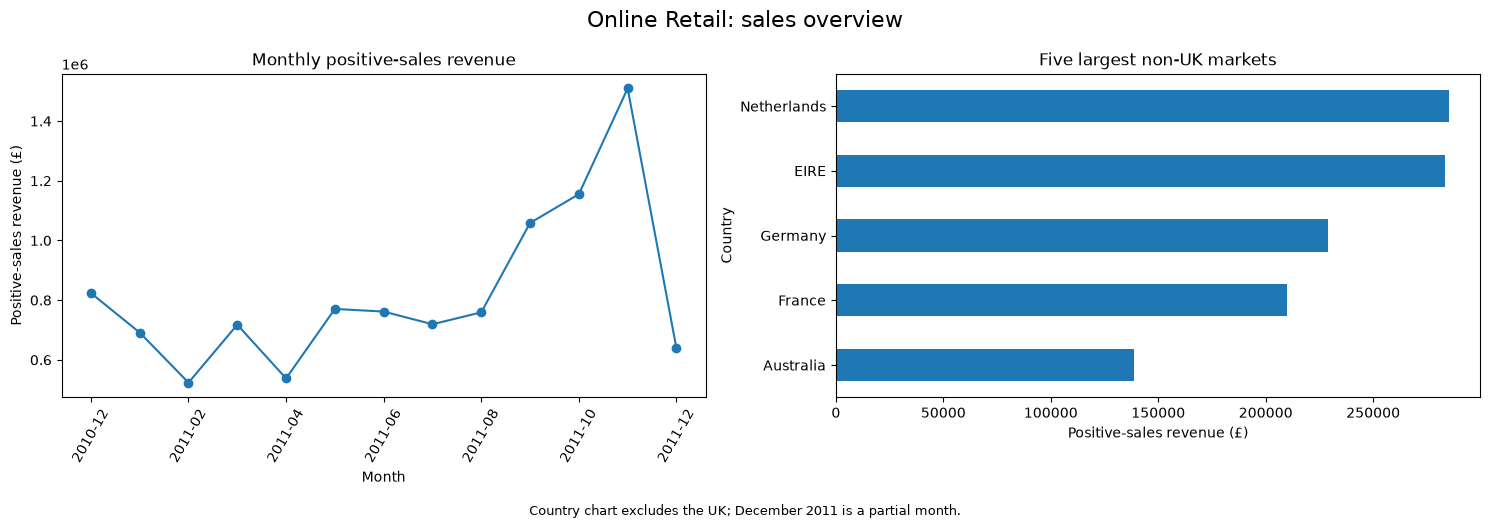

Saved: /Users/abepark/Documents/Codex/2026-10-28/referenced-chatgpt-conversation-this-is-an/ecommerce-sales-analysis/dashboard/week5_sales_dashboard.png


In [7]:
if monthly_revenue is None or top_non_uk is None:
    print("Finish Sections 4 and 5, then return to this cell.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    monthly_revenue.plot(ax=axes[0], marker="o")
    axes[0].set_title("Monthly positive-sales revenue")
    axes[0].set_xlabel("Month")
    axes[0].set_ylabel("Positive-sales revenue (£)")
    axes[0].tick_params(axis="x", rotation=60)

    # Sorting here places the largest bar at the top of the horizontal chart.
    top_non_uk.sort_values().plot.barh(ax=axes[1])
    axes[1].set_title("Five largest non-UK markets")
    axes[1].set_xlabel("Positive-sales revenue (£)")
    axes[1].set_ylabel("Country")

    fig.suptitle("Online Retail: sales overview", fontsize=16)
    fig.text(0.5, -0.03, "Country chart excludes the UK; December 2011 is a partial month.",
             ha="center", fontsize=9)
    fig.tight_layout()
    fig.savefig(dashboard_dir / "week5_sales_dashboard.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", dashboard_dir / "week5_sales_dashboard.png")

**Chart check:** Both the monthly line chart and the five-market horizontal bar chart should be visible. The revenue unit is pounds (£), and the note explains the UK exclusion and partial December.

**Your one-sentence chart reading:** Monthly positive-sales revenue fluctuated and peaked in November 2011, the highest full month. The Netherlands led the five non-UK markets shown. December 2011 cannot be compared directly with a full month.

## 7. Write a short analyst memo

Numbers matter when they support a decision. Use your results from Sections 2–6 and your Week 4 notebook. A **finding** says what the data shows; a **recommendation** suggests a next step.

**My memo:**

1. **Sales scale:** Positive-sales revenue was £10,666,684.54 across 19,960 distinct orders, or about £534 per order on average. The average can be pulled upward by unusually large orders.
2. **Time pattern:** November 2011 was the highest full month at £1,509,496.33. December 2011 includes only part of the month, so its lower total does not establish that sales declined after November.
3. **Market pattern:** Outside the UK, the Netherlands led with £285,446.34. The five largest non-UK markets represented 10.7% of all positive-sales revenue; the UK remains in that denominator.
4. **Recommendation:** I would investigate growth opportunities in the Netherlands because it had the highest positive-sales revenue outside the UK. A next step is to compare its order counts, typical order values, and product mix with other non-UK markets before testing a localized campaign.
5. **Limitation:** These figures describe positive-sales revenue, not net revenue or profit; cancellations and nonpositive lines were excluded. Missing customer IDs limit customer-level analysis, and December 2011 is incomplete.

## Optional investigation: Is every high-revenue code a product?

`StockCode` is a label. A high-revenue code might be a product, postage, or a manual adjustment. To see why this matters, first group by `StockCode` and sum `Revenue` as you did for countries. Then inspect the descriptions for the top codes before calling them “best-selling products.”

**Your turn:** Fill in the two lines below. `.nlargest(10)` keeps the ten highest values. `.isin(...)` makes a True/False mask for codes in your top-ten index. What do codes such as `DOT`, `M`, or `POST` appear to represent? This is an investigation, so do not delete rows from the main dashboard.

In [8]:
# Optional: replace None with your expressions.
revenue_by_code = None  # group by StockCode and sum Revenue
top_codes = None        # ten largest entries from revenue_by_code

if revenue_by_code is None or top_codes is None:
    print("Optional challenge: fill in both lines to inspect the top codes.")
else:
    display(top_codes)
    display(
        sales.loc[sales["StockCode"].isin(top_codes.index), ["StockCode", "Description"]]
        .drop_duplicates()
        .head(30)
    )

Optional challenge: fill in both lines to inspect the top codes.


**What I learned about StockCode:** ___

## Week 5 checklist

- [ ] I can explain `.sum()`, `.nunique()`, `.groupby()`, `.sort_values()`, and `.sort_index()` in my own words.
- [ ] My KPI values use orders, not invoice lines, for the order count.
- [ ] My dashboard shows both charts and is saved in `dashboard/`.
- [ ] My memo includes three numbered findings, a specific recommendation, and a limitation.
- [ ] I saved this notebook with **⌘S**. When ready, I can ask for a review before uploading Week 5 to GitHub.